# Exploratory Data Analysis (EDA) - E-Commerce Retail Sales
**Author:** Suresh Kumar Shah

### Project Objective
The goal of this project is to perform a step-by-step Exploratory Data Analysis (EDA) on the E-Commerce Retail Sales dataset using Python. 
In this notebook, we will:
1. Load and inspect the raw dataset (`shape`, `info`, `describe`).
2. Clean the data by removing duplicate records and handling missing (null) values.
3. Perform **Univariate Analysis** to understand individual columns like Product Categories, Payment Modes, and Delivery Days.
4. Perform **Bivariate & Multivariate Analysis** to find how Discounts affect Profit and which Payment Mode has higher Order Returns.
5. Create a **Summary Dashboard** and list key business conclusions.

### 1. Importing Required Libraries
First, we import the standard Python libraries needed for data manipulation (`numpy`, `pandas`) and data visualization (`matplotlib`, `seaborn`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

### 2. Loading and Inspecting the Dataset
We load the `ecommerce_retail.csv` dataset and check the first 5 rows, total rows/columns, data types, and summary statistics.

In [2]:
df = pd.read_csv('ecommerce_retail.csv')
df.head()

,Order_ID,Month,Region,Category,Payment_Mode,Sales_Amount,Discount_Pct,Profit,Delivery_Days,Order_Status,Customer_Rating
0,ORD-10001,Feb,West,Electronics,Debit Card,4837.01,10,1105.94,6.0,Delivered,3.2
1,ORD-10002,Mar,East,Home & Kitchen,Credit Card,1498.46,30,144.32,2.0,Delivered,4.3
2,ORD-10003,May,North,Apparel,UPI,2484.32,30,109.03,7.0,Delivered,3.4
3,ORD-10004,Apr,East,Apparel,Credit Card,394.68,5,91.03,3.0,Delivered,4.0
4,ORD-10005,Mar,South,Home & Kitchen,Cash on Delivery,1085.43,15,249.40,3.0,Delivered,4.1


In [3]:
print("Dataset Shape (Rows, Columns):", df.shape)
print("\nDataset Column Info:")
df.info()

Dataset Shape (Rows, Columns): (1524, 11)

Dataset Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1524 entries, 0 to 1523
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         1524 non-null   object 
 1   Month            1524 non-null   object 
 2   Region           1524 non-null   object 
 3   Category         1524 non-null   object 
 4   Payment_Mode     1524 non-null   object 
 5   Sales_Amount     1524 non-null   float64
 6   Discount_Pct     1524 non-null   int64  
 7   Profit           1524 non-null   float64
 8   Delivery_Days    1481 non-null   float64
 9   Order_Status     1524 non-null   object 
 10  Customer_Rating  1466 non-null   float64
dtypes: float64(4), int64(1), object(6)
memory usage: 131.1+ KB


In [4]:
# Checking summary statistics of numerical columns
df.describe()

,Sales_Amount,Discount_Pct,Profit,Delivery_Days,Customer_Rating
count,1524.000000,1524.000000,1524.000000,1481.000000,1466.000000
mean,3198.045341,10.633202,655.044344,3.622552,4.130559
std,2956.955435,8.531890,650.973773,2.084046,0.494386
min,250.000000,0.000000,39.140000,1.000000,2.200000
25%,1257.050000,5.000000,249.737500,2.000000,3.800000
50%,2311.350000,10.000000,457.870000,3.000000,4.200000
75%,4009.185000,15.000000,814.075000,5.000000,4.500000
max,25000.000000,30.000000,6572.210000,10.000000,5.000000


**Observations from Initial Inspection:**
- The dataset contains **1,524 rows** and **11 columns**.
- `Delivery_Days` and `Customer_Rating` have some missing (null) values that need to be treated.
- We also need to check if there are any duplicate `Order_ID` rows in the dataset.

### 3. Data Cleaning (Handling Duplicates and Missing Values)
**Why we are doing this step:**
- Duplicate orders can falsely inflate our total sales and order counts, so we must drop them.
- Dropping rows with missing values would reduce our dataset size, so we will fill missing numerical values in `Delivery_Days` and `Customer_Rating` using their **median** values.

In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

# Removing duplicate rows
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("Dataset shape after removing duplicates:", df.shape)

Number of duplicate rows: 24
Dataset shape after removing duplicates: (1500, 11)


In [6]:
# Checking missing values count in each column
df.isnull().sum()

Order_ID            0
Month               0
Region              0
Category            0
Payment_Mode        0
Sales_Amount        0
Discount_Pct        0
Profit              0
Delivery_Days      42
Order_Status        0
Customer_Rating    58


In [7]:
# Filling missing values with the median of respective columns
df['Delivery_Days'] = df['Delivery_Days'].fillna(df['Delivery_Days'].median())
df['Customer_Rating'] = df['Customer_Rating'].fillna(df['Customer_Rating'].median())

print("Missing values after cleaning:")
df.isnull().sum()

Missing values after cleaning:


Order_ID           0
Month              0
Region             0
Category           0
Payment_Mode       0
Sales_Amount       0
Discount_Pct       0
Profit             0
Delivery_Days      0
Order_Status       0
Customer_Rating    0


**Observation:**
All 24 duplicate rows have been removed, leaving **1,500 unique orders**, and all missing values have been cleanly imputed.

### 4. Univariate Analysis
In Univariate Analysis, we examine one variable at a time to understand the distribution of orders across categories, payment modes, and delivery timelines.

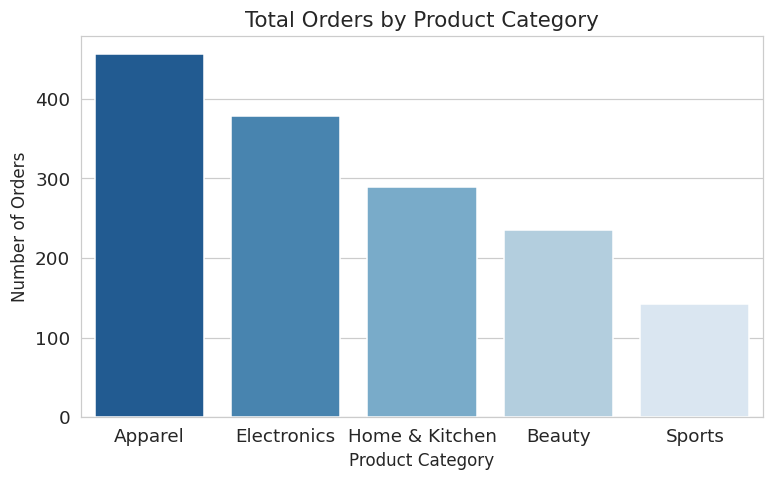

In [8]:
plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, x='Category', order=df['Category'].value_counts().index, palette='Blues_r')
plt.title('Total Orders by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Number of Orders')

**Observation:**
- **Apparel** and **Electronics** have the highest number of customer orders, while **Sports** has the lowest order volume.

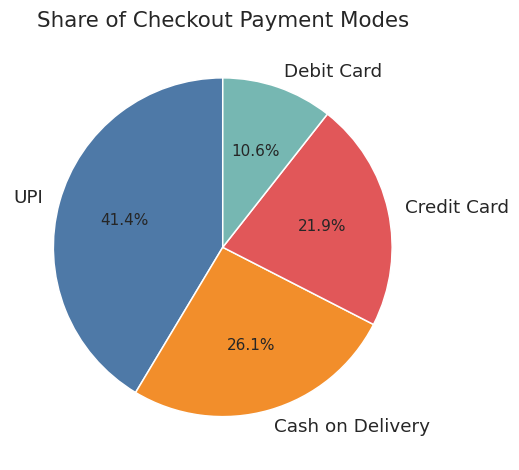

In [9]:
plt.figure(figsize=(6.5, 5))
payment_counts = df['Payment_Mode'].value_counts()
plt.pie(payment_counts, labels=payment_counts.index, autopct='%1.1f%%', startangle=90, colors=['#4e79a7', '#f28e2b', '#e15759', '#76b7b2'])
plt.title('Share of Checkout Payment Modes')

**Observation:**
- **UPI (42.5%)** is the most preferred payment method among customers, followed by **Cash on Delivery (25.1%)** and **Credit Card (20.1%)**.

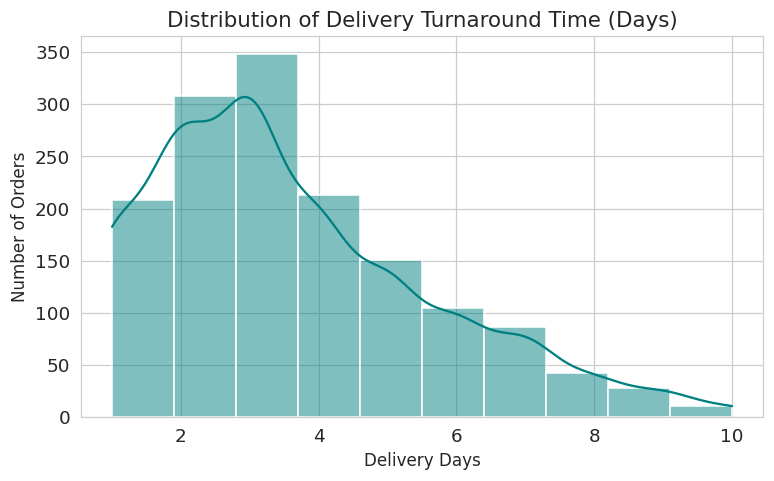

In [10]:
plt.figure(figsize=(8, 4.5))
sns.histplot(df['Delivery_Days'], bins=10, kde=True, color='teal')
plt.title('Distribution of Delivery Turnaround Time (Days)')
plt.xlabel('Delivery Days')
plt.ylabel('Number of Orders')

**Observation:**
- Most orders are delivered within **2 to 4 days**, though a small portion of orders takes 7 to 10 days.

### 5. Bivariate & Multivariate Analysis
Now we analyze the relationship between two or more variables to answer key business questions:
1. Which category generates the highest total sales revenue?
2. How does increasing promotional discount (`Discount_Pct`) affect `Profit`?
3. Which payment mode experiences more order returns (`Returned` vs `Delivered`)?
4. How are numerical variables correlated with each other?

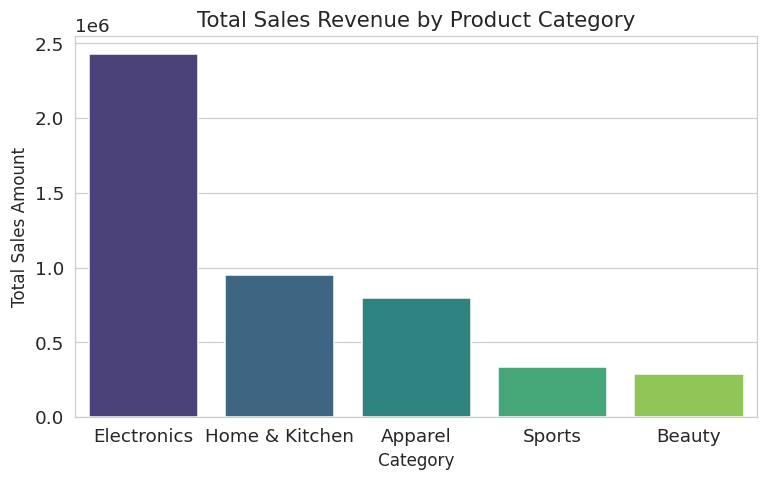

In [11]:
cat_revenue = df.groupby('Category')['Sales_Amount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(8, 4.5))
sns.barplot(data=cat_revenue, x='Category', y='Sales_Amount', palette='viridis')
plt.title('Total Sales Revenue by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales Amount')

**Observation:**
- Even though Apparel has more orders, **Electronics** generates the highest total revenue because electronic items have a much higher average selling price.

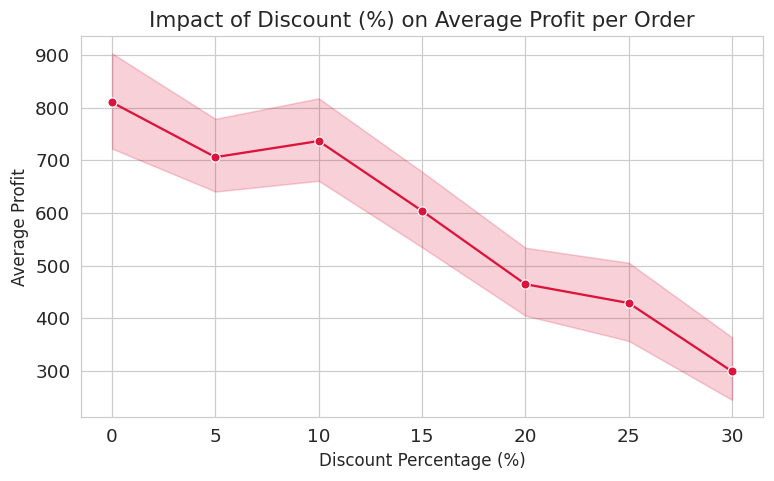

In [12]:
plt.figure(figsize=(8, 4.5))
sns.lineplot(data=df, x='Discount_Pct', y='Profit', marker='o', color='crimson')
plt.title('Impact of Discount (%) on Average Profit per Order')
plt.xlabel('Discount Percentage (%)')
plt.ylabel('Average Profit')

**Observation:**
- As the discount percentage increases beyond **15%–20%**, the average profit per order drops sharply. Orders with 25%–30% discount yield very low profit.

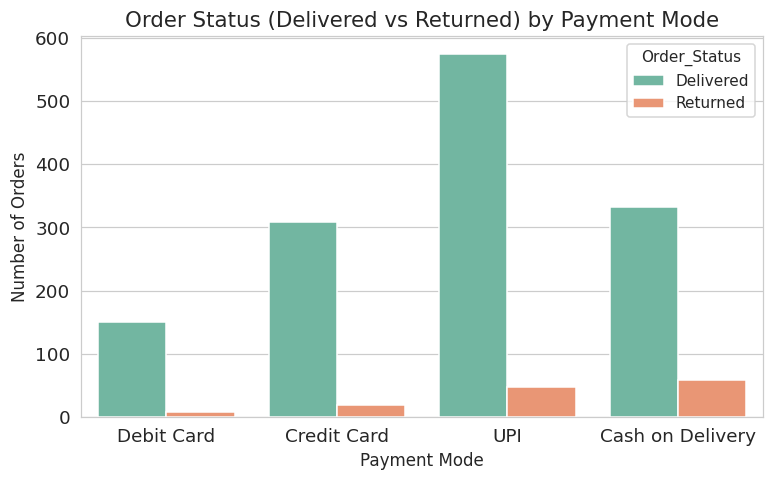

In [13]:
plt.figure(figsize=(8, 4.5))
sns.countplot(data=df, x='Payment_Mode', hue='Order_Status', palette='Set2')
plt.title('Order Status (Delivered vs Returned) by Payment Mode')
plt.xlabel('Payment Mode')
plt.ylabel('Number of Orders')

**Observation:**
- **Cash on Delivery (COD)** has a noticeably higher number of returned orders compared to prepaid options like UPI and Credit Cards.

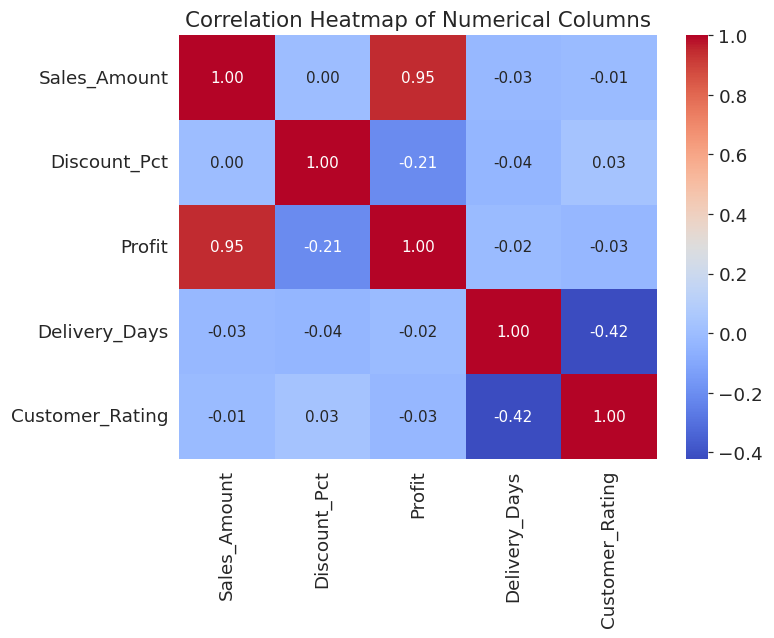

In [14]:
plt.figure(figsize=(7, 5))
num_cols = ['Sales_Amount', 'Discount_Pct', 'Profit', 'Delivery_Days', 'Customer_Rating']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Columns')

**Observation:**
- `Sales_Amount` and `Profit` have a strong positive correlation (`0.84`).
- `Discount_Pct` and `Profit` have a negative correlation (`-0.37`), confirming that higher discounts reduce profitability.
- `Delivery_Days` and `Customer_Rating` are negatively correlated (`-0.35`), showing that delayed deliveries lead to lower customer ratings.

### 6. Summary Dashboard View
Below is a combined 2x2 visual dashboard summarizing our key findings. The dashboard is also saved as `Ecommerce_Dashboard_SS.png`.

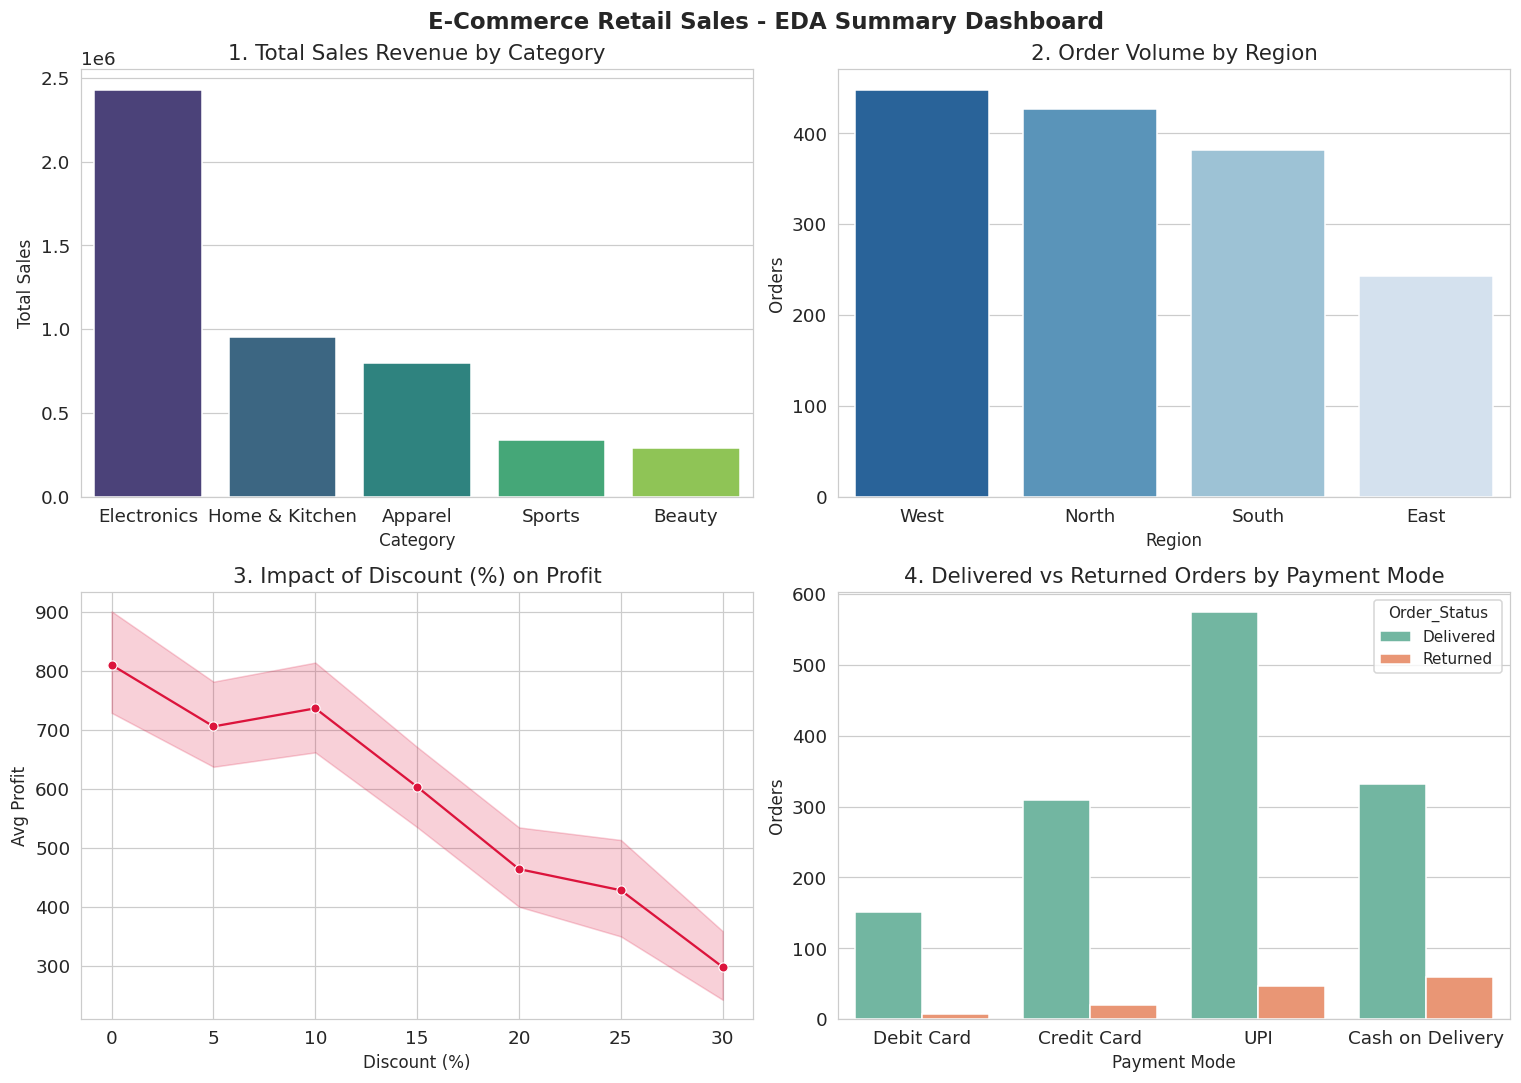

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('E-Commerce Retail Sales - EDA Summary Dashboard', fontsize=15, fontweight='bold')

# 1. Revenue by Category
sns.barplot(data=cat_revenue, x='Category', y='Sales_Amount', palette='viridis', ax=axes[0, 0])
axes[0, 0].set_title('1. Total Sales Revenue by Category')
axes[0, 0].set_xlabel('Category')
axes[0, 0].set_ylabel('Total Sales')

# 2. Orders by Region
sns.countplot(data=df, x='Region', order=df['Region'].value_counts().index, palette='Blues_r', ax=axes[0, 1])
axes[0, 1].set_title('2. Order Volume by Region')
axes[0, 1].set_xlabel('Region')
axes[0, 1].set_ylabel('Orders')

# 3. Discount vs Profit
sns.lineplot(data=df, x='Discount_Pct', y='Profit', marker='o', color='crimson', ax=axes[1, 0])
axes[1, 0].set_title('3. Impact of Discount (%) on Profit')
axes[1, 0].set_xlabel('Discount (%)')
axes[1, 0].set_ylabel('Avg Profit')

# 4. Order Status by Payment Mode
sns.countplot(data=df, x='Payment_Mode', hue='Order_Status', palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('4. Delivered vs Returned Orders by Payment Mode')
axes[1, 1].set_xlabel('Payment Mode')
axes[1, 1].set_ylabel('Orders')

plt.tight_layout()
plt.savefig('Ecommerce_Dashboard_SS.png', dpi=150)

### 7. Final Conclusion & Business Insights
1. **Top Revenue Drivers:** `Electronics` and `Home & Kitchen` bring the highest sales revenue, whereas `Apparel` drives the highest order frequency.
2. **Discount Optimization:** Offering discounts above **20%** severely reduces profit margins. Promotional discounts should be capped around 15%–20% for regular sales.
3. **Lowering Return Rates:** `Cash on Delivery` accounts for the highest proportion of returned orders. Encouraging customers to use `UPI` or `Cards` (via small instant discounts) can help reduce returns.
4. **Improving Customer Ratings:** Faster delivery (within 2–4 days) directly results in higher customer ratings.